# 91 · Language grounding test: does the policy follow the instruction, or just do the most common thing?

In [1]:
import os, numpy as np, torch, matplotlib.pyplot as plt, mujoco
from vlacourse import TableTop, evaluate
from vlacourse.torch_data import TableTopDataset
from vlacourse.lang import TextEmbedder, LangDataset, LangChunkRegression, LangChunkPolicy

from vlacourse import scene_dataset
SCENE = "sort"                      # TableTop scene tier (see vlacourse.SCENES)
DATA = scene_dataset(SCENE)          # 500 demos, recorded once with all CPU cores if missing
device = "cuda" if torch.cuda.is_available() else "cpu"
H = 16

def moved_object(env, start):
    d = {c: np.linalg.norm(env.cube_pos(c) - start[c]) for c in env.cube_colors}
    return max(d, key=d.get), max(d.values())

def grounding_test(policy, env, n=40, seed=80_000):
    """Same scene, three different 'pick up the {c} cube' instructions. Which cube actually moves?"""
    rows = []
    for k in range(n):
        for target in env.cube_colors:
            env.reset(seed=seed + k, task=dict(type="pick", obj=target, instruction=f"pick up the {target} cube"))
            start = {c: env.cube_pos(c) for c in env.cube_colors}
            policy.reset(); obs = env.observe(); done = False
            while not done:
                obs, _, done, info = env.step(policy.act(obs))
            moved, dist = moved_object(env, start)
            rows.append((target, moved if dist > 0.02 else "none", info["success"]))
    return rows

In [2]:
emb = TextEmbedder(device=device)
base = TableTopDataset(DATA, episodes=range(450), horizon=H)
ds = LangDataset(base, emb)
net = LangChunkRegression(lang_dim=emb.dim, horizon=H, fusion="film")
net.load_state_dict(torch.load("checkpoints/lang_film.pt", map_location=device)); net.to(device).eval()
env = TableTop(scene=SCENE, cameras=("front", "wrist"), image_size=(128, 128), seed=0)
rows = grounding_test(LangChunkPolicy(net, ds, env, emb, device=device, ensemble=True), env)

~/anaconda3/envs/vla/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 398/398 [00:00<00:00, 51349.87it/s]

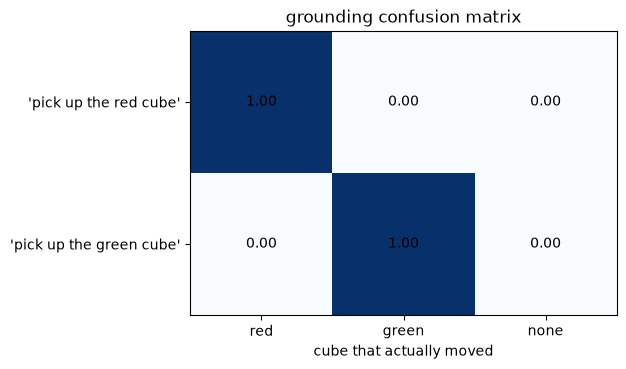

instruction followed (correct cube moved): 1.00   task success: 1.00


In [3]:
colors = env.cube_colors + ["none"]
M = np.zeros((len(env.cube_colors), len(colors)))
for target, moved, _ in rows:
    M[env.cube_colors.index(target), colors.index(moved)] += 1
M /= M.sum(1, keepdims=True)
plt.figure(figsize=(5.5, 4)); plt.imshow(M, cmap="Blues", vmin=0, vmax=1)
plt.xticks(range(len(colors)), colors); plt.yticks(range(len(env.cube_colors)), [f"'pick up the {c} cube'" for c in env.cube_colors])
for i in range(len(env.cube_colors)):
    for j in range(len(colors)):
        plt.text(j, i, f"{M[i, j]:.2f}", ha="center", va="center")
plt.xlabel("cube that actually moved"); plt.title("grounding confusion matrix"); plt.show()
print(f"instruction followed (correct cube moved): {np.mean([t == m for t, m, _ in rows]):.2f}   task success: {np.mean([s for *_, s in rows]):.2f}")

In [4]:
counter = {"pick up the red cube": 0}
r_null = evaluate(env, LangChunkPolicy(net, ds, env, emb, instruction_fn=lambda t: "do something", device=device, ensemble=True), n_episodes=40, seed=81_000)
print(f"with a meaningless instruction ('do something') the policy still 'succeeds' {r_null['success']:.2f} of the time (by luck of matching the sampled task)")

with a meaningless instruction ('do something') the policy still 'succeeds' 0.07 of the time (by luck of matching the sampled task)


### Watch it: same scene, same policy, different words
Nothing changes between the videos except the instruction. The robot should go for a different cube.

In [5]:
from vlacourse import showcase as sc
env.reset(seed=80_003); cols = list(env.cube_colors)
pol = LangChunkPolicy(net, ds, env, emb, device=device, ensemble=True)
sc.compare(env, {f"'pick up the {c} cube'": pol for c in cols}, seed=80_003, footer="same scene, same policy: only the instruction changes",
           per_policy_kw={f"'pick up the {c} cube'": dict(reset_kw=dict(task=dict(type="pick", obj=c, instruction=f"pick up the {c} cube"))) for c in cols},
           title="91 grounding: one scene, two instructions")

91 grounding: one scene, two instructions: 'pick up the red cube': success | 'pick up the green cube': success


[True, True]